# Ball-by-Ball Win Probability: the whole project in one notebook

This notebook walks through the project from the raw Cricsheet files to a calibrated, explained win probability, in the same order as the pipeline that runs on the Hadoop/Spark cluster:

| # | Section | What it does | Cluster equivalent in the repo |
|---|---|---|---|
| 1 | Setup | Paths, parameters, libraries | `etl/schema_utils.py` |
| 2 | Load the data | Read Cricsheet JSON and flatten it to one row per ball | `etl/flatten_matches.py` |
| 3 | Process and check the data | Types, missing values, legal balls, phases, dot balls | `mapreduce/phase_utils.py` |
| 4 | Explore and visualise | Formats, scoring patterns, dot balls, chase win rates | `dashboard/app.py` |
| 5 | Bowler statistics, MapReduce style | Runs the project's real mapper and reducer and checks them against pandas | `mapreduce/` |
| 6 | Feature extraction | Match state, momentum, rolling player form, context | `features/` |
| 7 | Chronological split | Train on the past, test on the future | `ml/train_win_probability.py` |
| 8 | Models | Logistic Regression, Gradient-Boosted Trees, Random Forest | `ml/compare_models.py` |
| 9 | Calibration | Are the percentages honest? | `ml/calibrate_win_probability.py` |
| 10 | Win Probability Added | Which ball swung the match? | `ml/compute_wpa.py` |
| 11 | Feature importance | What does the model rely on? | `ml/feature_importance.py` |
| 12 | Gender and level context | The missing-context finding | `ml/verify_context_adoption.py` |
| 13 | Batter vs bowler lookup | Why head-to-head is sparse | `features/matchup_lookup.py` |
| 14 | Full-data results from the cluster | Compare this notebook with the real run | `dashboard/data_cache/` |

**Important differences from the cluster run.** The cluster processes all 22,818 matches with Spark. This notebook runs on a laptop with pandas and scikit-learn, so by default it works on a **random sample of 2,500 limited-overs matches** (change `SAMPLE_MATCHES` in section 1; `None` uses everything, which needs roughly 8 GB of RAM and 15-25 minutes). The method is the same, but the numbers will differ a little from the full-data results, and section 14 puts the two side by side. Gradient-boosted trees here are scikit-learn's `HistGradientBoostingClassifier`, not Spark's `GBTClassifier`.

**How to run it:** `Kernel > Restart & Run All`. The first run parses the JSON files (about a minute) and caches the result in `notebooks/cache/`.

## 1. Setup

Libraries, paths and the two parameters worth knowing: how many matches to load and the random seed.

In [1]:
import json
import random
import subprocess
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")


def find_repo():
    """Walk upwards from the notebook's folder until the project root is found."""
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "CLAUDE.md").exists() and (p / "etl").is_dir():
            return p
    raise FileNotFoundError("Open this notebook from inside the cricket-analytics-scaffold repository.")


REPO = find_repo()
RAW = REPO / "data" / "raw" / "all_json"          # 22,818 Cricsheet match files (not in git)
CACHE = REPO / "notebooks" / "cache"               # parsed data is cached here
SNAPSHOTS = REPO / "dashboard" / "data_cache"      # full-data results exported from Hive
CACHE.mkdir(exist_ok=True)

# ---- parameters -------------------------------------------------------------------------------
SAMPLE_MATCHES = 2500      # number of limited-overs matches to load; None = all of them
SEED = 42
LIMITED_OVERS = {"ODI", "ODM", "T20", "IT20"}      # Test matches are excluded, as in the pipeline

# ---- one small palette, used for every chart ---------------------------------------------------
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)
print("repository :", REPO)
print("raw files  :", len(list(RAW.glob("*.json"))) if RAW.exists() else "NOT FOUND - download Cricsheet JSON into data/raw/all_json/")
print("sample size:", SAMPLE_MATCHES or "all matches")

python 3.14.6 | pandas 3.0.5 | numpy 2.5.1
repository : D:\bda\cricket-analytics-scaffold
raw files  : 22818
sample size: 2500


## 2. Load the data

Cricsheet publishes one JSON file per match. Each file is deeply nested: `info` (teams, venue, toss, outcome, player registry) and `innings`, which contain `overs`, which contain `deliveries`. Here is the shape of one T20 match.

In [2]:
def first_file_of_type(match_type):
    for path in sorted(RAW.glob("*.json")):
        with open(path, encoding="utf-8") as fh:
            doc = json.load(fh)
        if doc["info"].get("match_type") == match_type:
            return path, doc


path, doc = first_file_of_type("T20")
info = doc["info"]
print("file         :", path.name, "(match_id is the file name; it is not stored inside the JSON)")
print("top-level    :", list(doc.keys()))
print("info keys    :", list(info.keys()))
print("teams / venue:", info["teams"], "/", info.get("venue"))
print("outcome      :", info["outcome"])
print("innings      :", len(doc["innings"]), "-> keys of one innings:", list(doc["innings"][0].keys()))
print("\nfirst delivery of the first innings:")
print(json.dumps(doc["innings"][0]["overs"][0]["deliveries"][0], indent=1))
print("\na delivery with extras and a wicket looks like this:")
for ov in doc["innings"][0]["overs"]:
    hit = [d for d in ov["deliveries"] if "wickets" in d]
    if hit:
        print(json.dumps(hit[0], indent=1))
        break

file         : 1001349.json (match_id is the file name; it is not stored inside the JSON)
top-level    : ['meta', 'info', 'innings']
info keys    : ['balls_per_over', 'dates', 'event', 'gender', 'match_type', 'match_type_number', 'officials', 'outcome', 'overs', 'player_of_match', 'players', 'registry', 'season', 'team_type', 'teams', 'toss', 'venue']
teams / venue: ['Australia', 'Sri Lanka'] / Melbourne Cricket Ground
outcome      : {'by': {'wickets': 5}, 'winner': 'Sri Lanka'}
innings      : 2 -> keys of one innings: ['team', 'overs', 'powerplays']

first delivery of the first innings:
{
 "actual_delivery": "0.1",
 "batter": "AJ Finch",
 "bowler": "SL Malinga",
 "non_striker": "M Klinger",
 "runs": {
  "batter": 0,
  "extras": 0,
  "total": 0
 }
}

a delivery with extras and a wicket looks like this:
{
 "actual_delivery": "10.3",
 "batter": "M Klinger",
 "bowler": "PADLR Sandakan",
 "non_striker": "AJ Finch",
 "runs": {
  "batter": 0,
  "extras": 0,
  "total": 0
 },
 "wickets": [
  {

### Flatten to one row per delivery

The pipeline's `flatten_matches.py` does this with Spark (`posexplode` on innings, overs and deliveries). The function below does the same job with plain Python and keeps the same column names, so everything downstream reads like the cluster code.

Rules carried over from the project:

- `match_id` is the **file name stem**, kept as a string.
- Only limited-overs formats are kept (ODI, ODM, T20, IT20).
- Only the first two innings are read; super overs are ignored.
- Player names are resolved to Cricsheet person ids through the match's own registry (the registry only exists inside each match file, so the key is always match plus name).

In [3]:
DEL_COLS = ["match_id", "match_type", "overs_cap", "innings_num", "batting_team", "target_runs", "target_overs",
            "over", "delivery_idx", "batter", "bowler", "non_striker", "batter_id", "bowler_id", "non_striker_id",
            "runs_batter", "runs_extras", "runs_total", "extra_wides", "extra_noballs", "extra_byes",
            "extra_legbyes", "is_wicket", "num_wickets", "player_out", "player_out_id", "wicket_kind"]


def parse_match(path):
    """Return (match_row, delivery_rows) for a limited-overs match, or None for anything else."""
    with open(path, encoding="utf-8") as fh:
        doc = json.load(fh)
    info = doc["info"]
    match_type = info.get("match_type")
    if match_type not in LIMITED_OVERS:
        return None
    people = info.get("registry", {}).get("people", {})
    outcome = info.get("outcome", {})
    winner = outcome.get("winner")
    # outcome comes in several shapes; normalise to one result_type column
    result_type = "win" if winner else ("eliminator" if "eliminator" in outcome else outcome.get("result", "unknown"))
    match = dict(match_id=path.stem, match_type=match_type, gender=info.get("gender"),
                 team_type=info.get("team_type"), season=str(info.get("season")),
                 match_date=info["dates"][0], team1=info["teams"][0], team2=info["teams"][1],
                 venue=info.get("venue"), city=info.get("city"), overs_cap=info.get("overs"),
                 toss_winner=info.get("toss", {}).get("winner"), toss_decision=info.get("toss", {}).get("decision"),
                 winner=winner, result_type=result_type, method=outcome.get("method"))
    rows = []
    for innings_num, inn in enumerate(doc.get("innings", [])[:2], start=1):
        team = inn.get("team")
        target = inn.get("target", {})
        for ov in inn.get("overs", []):
            over = ov["over"]
            for idx, d in enumerate(ov["deliveries"]):
                runs, extras, wickets = d["runs"], d.get("extras", {}), d.get("wickets") or []
                batter, bowler, non_striker = d["batter"], d["bowler"], d.get("non_striker")
                out = wickets[0]["player_out"] if wickets else None
                rows.append((path.stem, match_type, info.get("overs"), innings_num, team,
                             target.get("runs"), target.get("overs"), over, idx,
                             batter, bowler, non_striker, people.get(batter), people.get(bowler), people.get(non_striker),
                             runs.get("batter", 0), runs.get("extras", 0), runs["total"],
                             extras.get("wides", 0), extras.get("noballs", 0), extras.get("byes", 0),
                             extras.get("legbyes", 0), bool(wickets), len(wickets),
                             out, people.get(out), wickets[0]["kind"] if wickets else None))
    return match, rows


def load_matches(sample, seed):
    cache = CACHE / f"parsed_{sample or 'all'}_{seed}.pkl"
    if cache.exists():
        print("loading cached parse:", cache.name)
        return pd.read_pickle(cache)
    files = sorted(RAW.glob("*.json"))
    random.Random(seed).shuffle(files)               # a random sample across years, formats and genders
    match_rows, delivery_rows, scanned = [], [], 0
    t0 = time.time()
    for path in files:
        scanned += 1
        parsed = parse_match(path)
        if parsed is None:
            continue
        match_rows.append(parsed[0])
        delivery_rows.extend(parsed[1])
        if sample and len(match_rows) >= sample:
            break
        if scanned % 2000 == 0:
            print(f"  scanned {scanned} files, kept {len(match_rows)} matches ({time.time() - t0:.0f}s)")
    matches = pd.DataFrame(match_rows)
    deliveries = pd.DataFrame(delivery_rows, columns=DEL_COLS)
    print(f"scanned {scanned} files in {time.time() - t0:.0f}s: {len(matches)} limited-overs matches, {len(deliveries):,} deliveries")
    pd.to_pickle((matches, deliveries), cache)
    return matches, deliveries


matches, deliveries = load_matches(SAMPLE_MATCHES, SEED)

loading cached parse: parsed_2500_42.pkl


In [4]:
# Ball order and the legal-ball counter, exactly as flatten_matches.py defines them:
# wides and no-balls are not legal deliveries, so they do not advance the ball count.
matches["match_date"] = pd.to_datetime(matches["match_date"])
matches["year"] = matches["match_date"].dt.year

deliveries["is_legal_ball"] = (deliveries["extra_wides"] == 0) & (deliveries["extra_noballs"] == 0)
by_innings = deliveries.groupby(["match_id", "innings_num"], sort=False)
deliveries["ball_seq"] = by_innings.cumcount() + 1
deliveries["balls_completed_in_innings"] = by_innings["is_legal_ball"].cumsum()

print(f"matches    : {matches.shape}   deliveries: {deliveries.shape}")
display(deliveries.head(8))

matches    : (2500, 17)   deliveries: (754345, 30)


,match_id,match_type,overs_cap,innings_num,batting_team,target_runs,target_overs,over,delivery_idx,batter,...,extra_byes,extra_legbyes,is_wicket,num_wickets,player_out,player_out_id,wicket_kind,is_legal_ball,ball_seq,balls_completed_in_innings
0,1174842,ODM,50,1,Papua New Guinea,NaN,NaN,0,0,TP Ura,...,0,0,False,0,NaN,NaN,NaN,True,1,1
1,1174842,ODM,50,1,Papua New Guinea,NaN,NaN,0,1,TP Ura,...,0,0,False,0,NaN,NaN,NaN,True,2,2
2,1174842,ODM,50,1,Papua New Guinea,NaN,NaN,0,2,TP Ura,...,0,0,False,0,NaN,NaN,NaN,True,3,3
3,1174842,ODM,50,1,Papua New Guinea,NaN,NaN,0,3,TP Ura,...,0,0,False,0,NaN,NaN,NaN,True,4,4
4,1174842,ODM,50,1,Papua New Guinea,NaN,NaN,0,4,TP Ura,...,0,0,False,0,NaN,NaN,NaN,True,5,5
5,1174842,ODM,50,1,Papua New Guinea,NaN,NaN,0,5,TP Ura,...,0,0,False,0,NaN,NaN,NaN,True,6,6
6,1174842,ODM,50,1,Papua New Guinea,NaN,NaN,1,0,A Vala,...,0,0,False,0,NaN,NaN,NaN,True,7,7
7,1174842,ODM,50,1,Papua New Guinea,NaN,NaN,1,1,A Vala,...,0,0,False,0,NaN,NaN,NaN,True,8,8


## 3. Process and check the data

Before any analysis, the data is checked. These checks mirror the "verify by counts, not by exit codes" rule used throughout the project.

In [5]:
print("Matches by format and gender")
display(pd.crosstab(matches["match_type"], matches["gender"], margins=True))

print("\nMatch result types (only 'win' has a usable label for the model)")
display(matches["result_type"].value_counts().to_frame("matches"))

print("\nColumns with missing values in deliveries (share of rows)")
nulls = deliveries.isna().mean()
display(nulls[nulls > 0].round(4).to_frame("share_missing"))

# invariants that must always hold
assert deliveries["match_id"].isin(matches["match_id"]).all(), "delivery without a match"
assert not deliveries.duplicated(["match_id", "innings_num", "ball_seq"]).any(), "duplicate ball key"
assert (deliveries["runs_total"] == deliveries["runs_batter"] + deliveries["runs_extras"]).all(), "run totals do not add up"
print("\nchecks passed: every delivery has a match, no duplicate (match, innings, ball), runs_total = batter + extras")

Matches by format and gender


gender,female,male,All
match_type,,,
IT20,10,28,38
ODI,78,316,394
ODM,51,192,243
T20,473,1352,1825
All,612,1888,2500



Match result types (only 'win' has a usable label for the model)


,matches
result_type,
win,2409
no result,69
eliminator,15
tie,7



Columns with missing values in deliveries (share of rows)


,share_missing
target_runs,0.5691
target_overs,0.5691
player_out,0.9570
player_out_id,0.9570
wicket_kind,0.9570



checks passed: every delivery has a match, no duplicate (match, innings, ball), runs_total = batter + extras


### Derived columns: phase, runs charged to the bowler, dot balls

These definitions are the project's invariants:

- **Phase** (0-indexed overs): T20/IT20 powerplay 0-5, middle 6-14, death 15+; ODI/ODM powerplay 0-9, middle 10-39, death 40+.
- **Runs charged to the bowler** = total runs minus byes and leg-byes. Wides and no-balls *are* charged.
- **Legal ball** = no wide and no no-ball.
- **Bowler's dot ball** = a legal ball on which the bowler is charged no runs (so a bye ball counts as a dot).

The phase column is computed with vectorised code for speed and then **checked against the project's own `get_phase` function** on a random sample.

In [6]:
sys.path.insert(0, str(REPO / "mapreduce"))
from phase_utils import get_phase            # the exact function the MapReduce mapper uses

is_t20 = deliveries["match_type"].isin(["T20", "IT20"])
o = deliveries["over"]
deliveries["phase"] = np.select([is_t20 & (o <= 5), is_t20 & (o <= 14), is_t20, o <= 9, o <= 39],
                                ["powerplay", "middle", "death", "powerplay", "middle"], default="death")

check = deliveries.sample(20000, random_state=1)
expected = [get_phase(int(a), b) for a, b in zip(check["over"], check["match_type"])]
assert (check["phase"].to_numpy() == np.array(expected)).all()
print("phase column agrees with phase_utils.get_phase on 20,000 random deliveries")

deliveries["runs_charged"] = deliveries["runs_total"] - deliveries["extra_byes"] - deliveries["extra_legbyes"]
deliveries["bowler_dot"] = deliveries["is_legal_ball"] & (deliveries["runs_charged"] == 0)
deliveries["family"] = np.where(is_t20, "T20", "ODI")        # T20+IT20 vs ODI+ODM

print(f"legal balls: {deliveries['is_legal_ball'].mean():.1%} of rows | dot balls: {deliveries.loc[deliveries.is_legal_ball, 'bowler_dot'].mean():.1%} of legal balls")

phase column agrees with phase_utils.get_phase on 20,000 random deliveries


legal balls: 96.4% of rows | dot balls: 47.7% of legal balls


## 4. Explore and visualise

What does the data look like? Six views that explain why the model needs the context it gets.

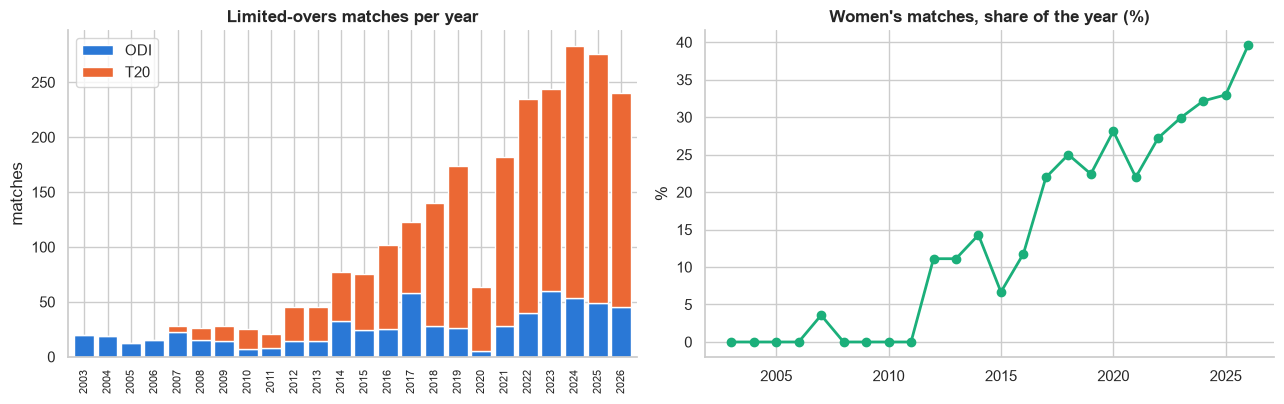

Women's cricket's share of matches has grown a lot, which is why a model that cannot tell men's from women's matches drifts.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

per_year = matches.assign(family=np.where(matches.match_type.isin(["T20", "IT20"]), "T20", "ODI")) \
                  .groupby(["year", "family"]).size().unstack(fill_value=0)
per_year.plot.bar(stacked=True, ax=axes[0], color=[BLUE, ORANGE], width=0.85)
axes[0].set(title="Limited-overs matches per year", xlabel="", ylabel="matches")
axes[0].tick_params(axis="x", rotation=90, labelsize=8)
axes[0].legend(title="")

share = matches.groupby("year")["gender"].apply(lambda s: (s == "female").mean() * 100)
axes[1].plot(share.index, share.values, color=GREEN, marker="o", lw=2)
axes[1].set(title="Women's matches, share of the year (%)", xlabel="", ylabel="%")
plt.tight_layout()
plt.show()
print("Women's cricket's share of matches has grown a lot, which is why a model that cannot tell men's from women's matches drifts.")

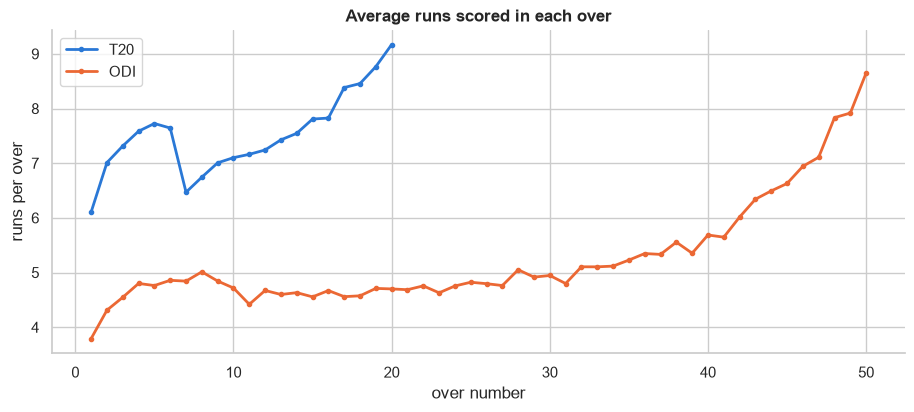

Scoring accelerates at the end of the innings: the same number of runs needed means something different early and late.


In [8]:
legal = deliveries[deliveries["innings_num"].isin([1, 2])]
per_over = (legal.groupby(["family", "match_id", "innings_num", "over"])["runs_total"].sum().reset_index()
                 .groupby(["family", "over"])["runs_total"].agg(["mean", "count"]).reset_index())
per_over = per_over[per_over["count"] >= 200]                 # drop overs with very few observations

fig, ax = plt.subplots(figsize=(11, 4.2))
for fam, colour in [("T20", BLUE), ("ODI", ORANGE)]:
    d = per_over[per_over.family == fam]
    ax.plot(d["over"] + 1, d["mean"], marker="o", ms=3, lw=2, color=colour, label=fam)
ax.set(title="Average runs scored in each over", xlabel="over number", ylabel="runs per over")
ax.legend()
plt.show()
print("Scoring accelerates at the end of the innings: the same number of runs needed means something different early and late.")

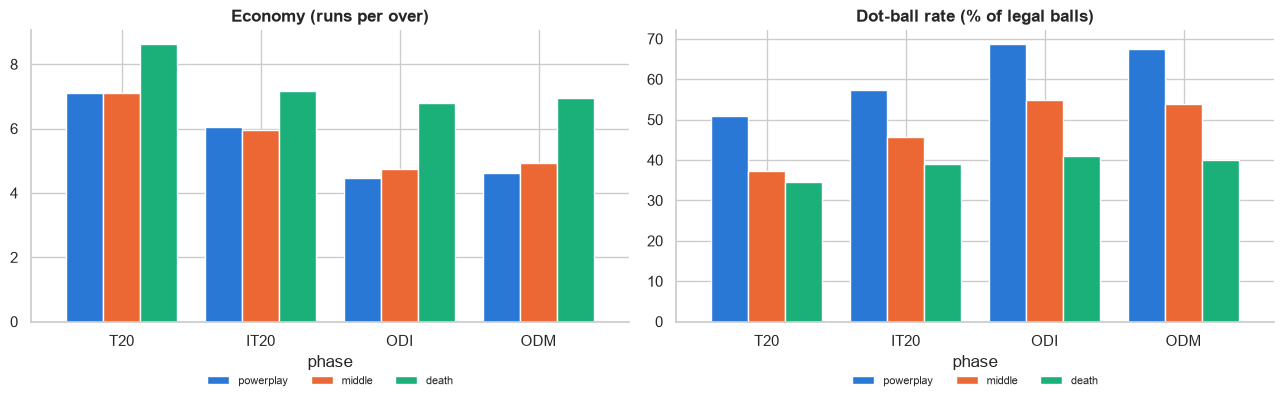

,format,phase,this notebook (sample),cluster (all matches),difference
0,T20,powerplay,51.0,50.8,0.2
1,T20,middle,37.4,37.2,0.2
2,T20,death,34.4,34.0,0.4
3,ODI,powerplay,68.7,68.1,0.6
4,ODI,middle,54.7,54.0,0.7
5,ODI,death,41.1,40.7,0.4


In [9]:
# league-wide economy and dot-ball rate by format and phase (bowler's view)
ph = (deliveries.groupby(["match_type", "phase"])
      .agg(runs=("runs_charged", "sum"), balls=("is_legal_ball", "sum"), dots=("bowler_dot", "sum")))
ph["economy"] = ph["runs"] * 6 / ph["balls"]
ph["dot_pct"] = 100 * ph["dots"] / ph["balls"]
order = ["powerplay", "middle", "death"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, title in [(axes[0], "economy", "Economy (runs per over)"), (axes[1], "dot_pct", "Dot-ball rate (% of legal balls)")]:
    pivot = ph[col].unstack("phase")[order].loc[["T20", "IT20", "ODI", "ODM"]]
    pivot.plot.bar(ax=ax, color=[BLUE, ORANGE, GREEN], width=0.8)
    ax.set(title=title, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="phase", fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

# sanity check against the full-data MapReduce run (22,818 matches) reported in CLAUDE.md
cluster = {("T20", "powerplay"): 50.8, ("T20", "middle"): 37.2, ("T20", "death"): 34.0,
           ("ODI", "powerplay"): 68.1, ("ODI", "middle"): 54.0, ("ODI", "death"): 40.7}
cmp = pd.DataFrame([(k[0], k[1], ph.loc[k, "dot_pct"], v) for k, v in cluster.items()],
                   columns=["format", "phase", "this notebook (sample)", "cluster (all matches)"]).round(1)
cmp["difference"] = (cmp.iloc[:, 2] - cmp.iloc[:, 3]).round(1)
display(cmp)

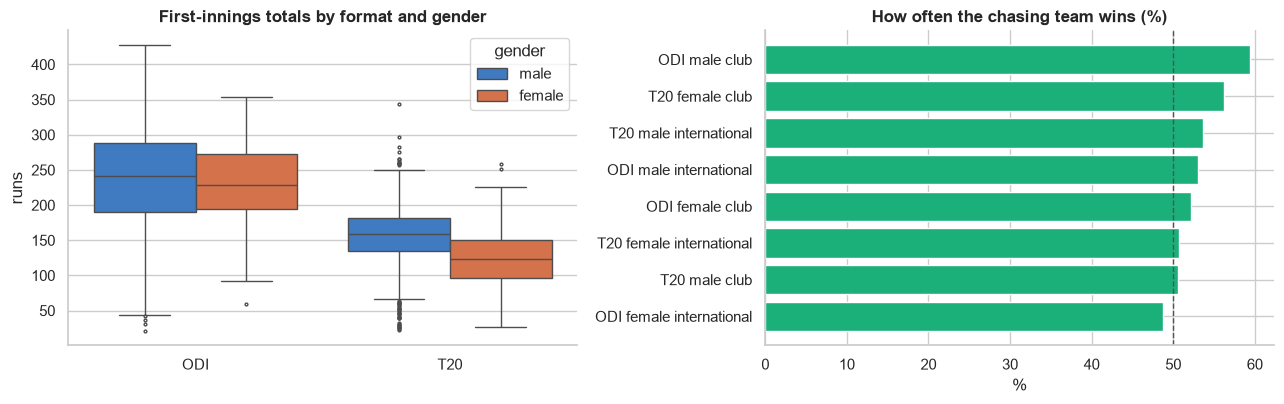

Overall the chasing team wins 52.3% of decided matches (label balance is close to 50/50, so there is no imbalance problem).


In [10]:
innings1 = (deliveries[deliveries.innings_num == 1].groupby("match_id")["runs_total"].sum().rename("first_innings_total"))
tot = matches.set_index("match_id").join(innings1).dropna(subset=["first_innings_total"])
tot["family"] = np.where(tot.match_type.isin(["T20", "IT20"]), "T20", "ODI")
tot = tot[tot.first_innings_total > 20]                         # drop abandoned or tiny innings

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(data=tot, x="family", y="first_innings_total", hue="gender", palette=[BLUE, ORANGE], ax=axes[0], fliersize=2)
axes[0].set(title="First-innings totals by format and gender", xlabel="", ylabel="runs")

chaser = (deliveries[deliveries.innings_num == 2].groupby("match_id")["batting_team"].first().rename("chaser"))
w = matches.set_index("match_id").join(chaser).dropna(subset=["winner", "chaser"])
w["chaser_won"] = (w.winner == w.chaser).astype(int)
w["family"] = np.where(w.match_type.isin(["T20", "IT20"]), "T20", "ODI")
rate = w.groupby(["family", "gender", "team_type"])["chaser_won"].agg(["mean", "count"]).reset_index()
rate["segment"] = rate["family"] + " " + rate["gender"] + " " + rate["team_type"]
rate = rate[rate["count"] >= 30].sort_values("mean")
axes[1].barh(rate["segment"], rate["mean"] * 100, color=GREEN)
axes[1].axvline(50, color=GREY, ls="--", lw=1)
axes[1].set(title="How often the chasing team wins (%)", xlabel="%", ylabel="")
plt.tight_layout()
plt.show()
print(f"Overall the chasing team wins {w.chaser_won.mean():.1%} of decided matches (label balance is close to 50/50, so there is no imbalance problem).")

## 5. Bowler statistics, MapReduce style

On the cluster, bowler economy by phase is a **Hadoop Streaming MapReduce** job: a *mapper* turns every delivery into a `key -> values` record, Hadoop sorts by key, and a *reducer* adds up each key's records. The project's real `mapper.py` and `reducer.py` are plain Python reading standard input, so they can run right here.

This section feeds them a 300-match subset exactly the way Hadoop would (map, sort by key, reduce), and then **checks the result against an independent pandas group-by**. It is the same idea as `mapreduce/verify_with_spark.py`, which checks all 33,107 rows of the real run in Spark.

In [11]:
import io
import os

MR_COLS = ["match_id", "match_type", "overs_cap", "innings_num", "over", "bowler", "bowler_id",
           "runs_total", "extra_wides", "extra_noballs", "extra_byes", "extra_legbyes", "is_wicket"]   # the mapper's input contract
OUT_COLS = ["bowler_id", "match_type", "phase", "runs_conceded", "legal_balls", "overs_bowled", "wickets",
            "economy", "balls_per_wicket", "dot_balls", "dot_ball_pct"]

subset_ids = matches["match_id"].sample(300, random_state=3)
sub = deliveries[deliveries["match_id"].isin(subset_ids)]

# 1. write the deliveries as tab-separated text (what flatten_matches.py exports for Hadoop)
tsv = sub[MR_COLS].astype(object).where(sub[MR_COLS].notna(), "")
tsv["is_wicket"] = tsv["is_wicket"].map({True: "true", False: "false"})
text = "\n".join(tsv.astype(str).agg("\t".join, axis=1)) + "\n"

env = {**os.environ, "PYTHONIOENCODING": "utf-8"}
run = lambda script, data: subprocess.run([sys.executable, script], input=data, capture_output=True,
                                          cwd=REPO / "mapreduce", env=env, check=True)

# 2. map -> 3. shuffle and sort by key (Hadoop does this between the two steps) -> 4. reduce
mapped = run("mapper.py", text.encode("utf-8"))
sorted_lines = sorted(mapped.stdout.decode("utf-8").splitlines())
reduced = run("reducer.py", ("\n".join(sorted_lines) + "\n").encode("utf-8"))

print(f"input lines: {len(sub):,}  ->  mapper output lines: {len(sorted_lines):,}")
print("mapper log :", mapped.stderr.decode().strip() or "no bad lines", "(rows without a bowler id are skipped and counted)")
mr = pd.read_csv(io.StringIO(reduced.stdout.decode("utf-8")), sep="\t", header=None, names=OUT_COLS, keep_default_na=False,
                 dtype={"bowler_id": str})
for c in ["economy", "balls_per_wicket", "dot_ball_pct"]:
    mr[c] = pd.to_numeric(mr[c], errors="coerce")
print(f"reducer output rows: {len(mr):,} (one per bowler, format and phase)")
display(mr.sort_values("legal_balls", ascending=False).head(6))

input lines: 92,294  ->  mapper output lines: 92,294
mapper log : no bad lines (rows without a bowler id are skipped and counted)
reducer output rows: 4,681 (one per bowler, format and phase)


,bowler_id,match_type,phase,runs_conceded,legal_balls,overs_bowled,wickets,economy,balls_per_wicket,dot_balls,dot_ball_pct
679,249d60c9,ODI,middle,225,270,45.000,13,5.0000,20.77,139,51.48
2871,9ab63e7b,ODI,middle,110,179,29.833,4,3.6872,44.75,105,58.66
1852,64c34cd0,ODI,middle,92,173,28.833,7,3.1908,24.71,122,70.52
2864,9a963804,ODI,middle,152,168,28.000,4,5.4286,42.00,78,46.43
4078,e087956b,ODI,middle,138,155,25.833,4,5.3419,38.75,72,46.45
206,0b60eb09,ODI,middle,97,151,25.167,6,3.8543,25.17,82,54.30


In [12]:
# independent check: the same numbers with a pandas group-by
ref = (sub.dropna(subset=["bowler_id"]).groupby(["bowler_id", "match_type", "phase"])
          .agg(runs_conceded=("runs_charged", "sum"), legal_balls=("is_legal_ball", "sum"),
               wickets=("is_wicket", "sum"), dot_balls=("bowler_dot", "sum")).reset_index())
both = mr.merge(ref, on=["bowler_id", "match_type", "phase"], how="outer", suffixes=("_mr", "_pd"), indicator=True)

only_one_side = (both["_merge"] != "both").sum()
bad = {c: int((both[f"{c}_mr"] != both[f"{c}_pd"]).sum()) for c in ["runs_conceded", "legal_balls", "wickets", "dot_balls"]}
print(f"keys present on only one side: {only_one_side}")
print("mismatches per column        :", bad)
assert only_one_side == 0 and not any(bad.values())
print("\nVERIFIED: the project's mapper and reducer agree with pandas on every bowler-phase row.")

keys present on only one side: 0
mismatches per column        : {'runs_conceded': 0, 'legal_balls': 0, 'wickets': 0, 'dot_balls': 0}

VERIFIED: the project's mapper and reducer agree with pandas on every bowler-phase row.


## 6. Feature extraction

The model predicts one thing: **after this ball, does the team batting second go on to win?** Each second-innings delivery becomes a training row. The label is `1` if the chasing team won. Abandoned or no-result matches have no label and are dropped.

The features come in four groups. They are the same groups the cluster uses (`features/match_state_features.py`, `features/player_form_features.py`, `features/build_training_table.py`).

| Group | Examples | Why it matters |
|---|---|---|
| Match state | runs required, balls and wickets left, current and required run rate | The core of every chase |
| Recent momentum | runs and wickets in the last 12 and 30 balls | Is the batting side on top right now? |
| Player form | striker and non-striker strike rate, bowler economy over the previous 10 matches | Who is batting and bowling? |
| Context | `is_female`, `is_international`, match format | Who is playing, and at what level? |

### 6.1 Chase rows and match state

In [13]:
chase = deliveries[(deliveries["innings_num"] == 2) & deliveries["target_runs"].notna()].copy()
meta = matches[["match_id", "match_date", "season", "gender", "team_type", "winner", "overs_cap"]] \
    .rename(columns={"overs_cap": "match_overs_cap"})
n_before = len(chase)
chase = chase.merge(meta, on="match_id", how="left")
assert len(chase) == n_before, "the join multiplied rows"

chase = chase[chase["winner"].notna()].copy()                                  # no result -> no label
chase["label"] = (chase["winner"] == chase["batting_team"]).astype(int)        # did the chasing team win?
# rain-shortened matches: prefer the innings' own over limit when present
chase["innings_overs_cap"] = chase["target_overs"].fillna(chase["overs_cap"]).fillna(chase["match_overs_cap"])
chase = chase[chase["innings_overs_cap"] > 1].reset_index(drop=True)            # excludes super overs

g = chase.groupby("match_id", sort=False)
assert (g["ball_seq"].diff().dropna() > 0).all(), "rows are not in ball order"

# --- state of the innings as of each ball ---
chase["current_score"] = g["runs_total"].cumsum()
chase["wickets_down"] = g["num_wickets"].cumsum()
chase["balls_remaining"] = (chase["innings_overs_cap"] * 6 - chase["balls_completed_in_innings"]).clip(lower=0)
chase["wickets_remaining"] = 10 - chase["wickets_down"]
chase["current_run_rate"] = np.where(chase["balls_completed_in_innings"] > 0,
                                     chase["current_score"] * 6.0 / chase["balls_completed_in_innings"].clip(lower=1), np.nan)
chase["runs_required"] = (chase["target_runs"] - chase["current_score"]).clip(lower=0)
chase["required_run_rate"] = np.where(chase["balls_remaining"] > 0,
                                      chase["runs_required"] * 6.0 / chase["balls_remaining"].clip(lower=1), np.nan)

# --- recent momentum: the window ENDS ON THE PREVIOUS BALL, so the current ball never leaks in ---
for n in (12, 30):
    for src, name in [("runs_total", "runs"), ("num_wickets", "wickets")]:
        c = chase.groupby("match_id", sort=False)[src].cumsum()
        lagged = c.groupby(chase["match_id"], sort=False).shift(n + 1).fillna(0)
        chase[f"{name}_last_{n}"] = (c - chase[src]) - lagged
print(f"chase rows: {len(chase):,} from {chase.match_id.nunique():,} matches; chaser won in {chase.groupby('match_id').label.first().mean():.1%} of them")
display(chase[["match_id", "over", "current_score", "wickets_down", "balls_remaining", "runs_required",
               "current_run_rate", "required_run_rate", "runs_last_12", "wickets_last_12", "label"]].iloc[[0, 30, 60, 90, 110]].round(2))

chase rows: 321,518 from 2,250 matches; chaser won in 52.3% of them


,match_id,over,current_score,wickets_down,balls_remaining,runs_required,current_run_rate,required_run_rate,runs_last_12,wickets_last_12,label
0,1174842,0,0,1,299.0,222.0,0.00,4.45,0.0,0.0,0
30,1174842,4,15,3,272.0,207.0,3.21,4.57,8.0,1.0,0
60,1174842,9,25,6,243.0,197.0,2.63,4.86,2.0,3.0,0
90,1174842,13,42,6,218.0,180.0,3.07,4.95,8.0,0.0,0
110,1174842,16,46,6,198.0,176.0,2.71,5.33,3.0,0.0,0


**Leakage check.** A window that ends on the previous row is easy to get wrong, so the momentum columns are verified against a brute-force recomputation: for 500 random balls, sum the runs and wickets of the preceding 12 and 30 balls directly and compare.

In [14]:
rng = np.random.default_rng(0)
pos = chase.groupby("match_id", sort=False).cumcount()
runs_by_match = {m: grp["runs_total"].to_numpy() for m, grp in chase.groupby("match_id", sort=False)}
wkts_by_match = {m: grp["num_wickets"].to_numpy() for m, grp in chase.groupby("match_id", sort=False)}

bad = 0
for i in rng.choice(len(chase), 500, replace=False):
    m, p = chase.at[i, "match_id"], pos[i]
    for n in (12, 30):
        bad += runs_by_match[m][max(0, p - n):p].sum() != chase.at[i, f"runs_last_{n}"]
        bad += wkts_by_match[m][max(0, p - n):p].sum() != chase.at[i, f"wickets_last_{n}"]
print(f"momentum check on 500 random balls x 2 windows x 2 measures: {bad} mismatches")
assert bad == 0

momentum check on 500 random balls x 2 windows x 2 measures: 0 mismatches


### 6.2 Rolling player form, with no leakage

"What was this player's form *going into* this match?" For every (player, match) the form is the total over the player's **previous 10 matches**, so the current match never contributes to its own average. A debutant has unknown form (a missing value, not zero), which the model's imputer fills later.

Computed per match first (runs, balls faced, dismissals, runs conceded, balls bowled, wickets), then rolled with a window that ends one match back.

In [15]:
BOWLER_WICKETS = ["bowled", "caught", "lbw", "stumped", "caught and bowled", "hit wicket"]   # run-outs are not the bowler's
FORM_WINDOW = 10

d = deliveries[["match_id", "batter_id", "bowler_id", "player_out_id", "runs_batter", "extra_wides",
                "wicket_kind", "runs_charged", "is_legal_ball"]].copy()
d["faced"] = (d["extra_wides"] == 0).astype(int)                       # a wide is not a ball faced
d["legal"] = d["is_legal_ball"].astype(int)
d["bowler_wkt"] = d["wicket_kind"].isin(BOWLER_WICKETS).astype(int)

bat = (d.dropna(subset=["batter_id"]).groupby(["match_id", "batter_id"])
         .agg(runs_scored=("runs_batter", "sum"), balls_faced=("faced", "sum")).reset_index()
         .rename(columns={"batter_id": "player_id"}))
out = (d.dropna(subset=["player_out_id"]).groupby(["match_id", "player_out_id"]).size().rename("dismissals").reset_index()
         .rename(columns={"player_out_id": "player_id"}))
bowl = (d.dropna(subset=["bowler_id"]).groupby(["match_id", "bowler_id"])
          .agg(runs_conceded=("runs_charged", "sum"), balls_bowled=("legal", "sum"), wickets_taken=("bowler_wkt", "sum")).reset_index()
          .rename(columns={"bowler_id": "player_id"}))
STATS = ["runs_scored", "balls_faced", "dismissals", "runs_conceded", "balls_bowled", "wickets_taken"]

pm = (bat.merge(out, on=["match_id", "player_id"], how="outer").merge(bowl, on=["match_id", "player_id"], how="outer")
         .fillna({c: 0 for c in STATS}))
pm = pm.merge(matches[["match_id", "match_date"]], on="match_id", how="left")
pm = pm.sort_values(["player_id", "match_date", "match_id"]).reset_index(drop=True)      # match_id breaks same-day ties

gp = pm.groupby("player_id", sort=False)
for col in STATS:
    c = gp[col].cumsum()
    # sum over the previous FORM_WINDOW matches = cumulative up to the previous match minus cumulative before the window
    pm["form_" + col] = (c - pm[col]) - c.groupby(pm["player_id"], sort=False).shift(FORM_WINDOW + 1).fillna(0)
pm["matches_in_window"] = np.minimum(gp.cumcount(), FORM_WINDOW)

# nulls rather than zeros for players with no history: unknown form is not bad form
pm["rolling_strike_rate"] = np.where(pm["form_balls_faced"] > 0, pm["form_runs_scored"] * 100.0 / pm["form_balls_faced"].clip(lower=1), np.nan)
pm["rolling_batting_avg"] = np.where(pm["form_dismissals"] > 0, pm["form_runs_scored"] / pm["form_dismissals"].clip(lower=1), np.nan)
pm["rolling_economy"] = np.where(pm["form_balls_bowled"] > 0, pm["form_runs_conceded"] * 6.0 / pm["form_balls_bowled"].clip(lower=1), np.nan)
print(f"{len(pm):,} (player, match) rows for {pm.player_id.nunique():,} players; "
      f"{(pm.matches_in_window == 0).mean():.0%} of rows have no history yet")
display(pm[pm.matches_in_window >= 5].head(4)[["player_id", "match_date", "matches_in_window", "rolling_strike_rate", "rolling_batting_avg", "rolling_economy"]].round(2))

52,034 (player, match) rows for 8,566 players; 16% of rows have no history yet


,player_id,match_date,matches_in_window,rolling_strike_rate,rolling_batting_avg,rolling_economy
9,00321fff,2022-08-31,5,60.0,4.5,7.20
10,00321fff,2023-10-31,6,60.0,4.5,7.46
11,00321fff,2026-06-21,7,80.0,8.0,7.65
19,003d49e6,2023-08-06,5,100.0,19.0,8.88


In [16]:
# brute-force leakage check: recompute 150 random (player, match) forms using ONLY strictly earlier matches
sample_rows = pm[pm["matches_in_window"] > 0].sample(150, random_state=5)
bad = 0
for _, r in sample_rows.iterrows():
    hist = pm[(pm.player_id == r.player_id)]
    hist = hist[(hist.match_date < r.match_date) | ((hist.match_date == r.match_date) & (hist.match_id < r.match_id))].tail(FORM_WINDOW)
    for col in STATS:
        bad += abs(hist[col].sum() - r["form_" + col]) > 1e-9
print(f"form check on 150 random (player, match) rows x 6 measures: {bad} mismatches (history = previous 10 matches only)")
assert bad == 0

# attach form to each ball: striker, non-striker and bowler
n_before = len(chase)
def attach(frame, id_col, mapping):
    f = pm[["player_id", "match_id"] + list(mapping)].rename(columns={"player_id": id_col, **mapping})
    out = frame.merge(f, on=[id_col, "match_id"], how="left")
    assert len(out) == n_before, "form join multiplied rows"
    return out

chase = attach(chase, "batter_id", {"rolling_strike_rate": "striker_rolling_sr", "rolling_batting_avg": "striker_rolling_avg"})
chase = attach(chase, "non_striker_id", {"rolling_strike_rate": "nonstriker_rolling_sr"})
chase = attach(chase, "bowler_id", {"rolling_economy": "bowler_rolling_econ"})
print("form attached; share of balls with unknown form:",
      chase[["striker_rolling_sr", "nonstriker_rolling_sr", "bowler_rolling_econ"]].isna().mean().round(2).to_dict())

form check on 150 random (player, match) rows x 6 measures: 0 mismatches (history = previous 10 matches only)


form attached; share of balls with unknown form: {'striker_rolling_sr': 0.14, 'nonstriker_rolling_sr': 0.14, 'bowler_rolling_econ': 0.17}


### 6.3 Derived ratios, context and the final feature matrix

A few ratios carry most of the signal in a chase. Missing values are filled the way the cluster does: the current run rate is 0 before the first ball, the required rate is capped at 36 when no balls remain, and runs per wicket needed falls back to runs required when all wickets are gone.

In [17]:
RRR_CAP = 36.0
chase["current_run_rate"] = chase["current_run_rate"].fillna(0.0)
chase["required_run_rate"] = chase["required_run_rate"].fillna(RRR_CAP).clip(upper=RRR_CAP)
chase["run_rate_diff"] = chase["required_run_rate"] - chase["current_run_rate"]
chase["resources_left"] = chase["balls_remaining"] * chase["wickets_remaining"]          # a Duckworth-Lewis-style quantity
chase["runs_per_wicket_needed"] = np.where(chase["wickets_remaining"] > 0,
                                           chase["runs_required"] / chase["wickets_remaining"].clip(lower=1), chase["runs_required"])
# context: who is playing, and at what level
chase["is_female"] = (chase["gender"] == "female").astype(float)
chase["is_international"] = (chase["team_type"] == "international").astype(float)
for mt in ["T20", "IT20", "ODI", "ODM"]:
    chase[f"mt_{mt}"] = (chase["match_type"] == mt).astype(float)

STATE = ["current_score", "wickets_down", "wickets_remaining", "balls_remaining", "current_run_rate",
         "runs_required", "required_run_rate", "run_rate_diff", "resources_left", "runs_per_wicket_needed"]
MOMENTUM = ["runs_last_12", "wickets_last_12", "runs_last_30", "wickets_last_30"]
FORM = ["striker_rolling_sr", "striker_rolling_avg", "nonstriker_rolling_sr", "bowler_rolling_econ"]
CONTEXT = ["is_female", "is_international"]
FORMAT = ["mt_T20", "mt_IT20", "mt_ODI", "mt_ODM"]
FEATURES = STATE + MOMENTUM + FORM + CONTEXT + FORMAT
LABEL = "label"

print(f"{len(FEATURES)} features: {len(STATE)} state + {len(MOMENTUM)} momentum + {len(FORM)} form + {len(CONTEXT)} context + {len(FORMAT)} format")
print(f"training table: {len(chase):,} rows, {chase.match_id.nunique():,} chases | label balance: {chase[LABEL].mean():.1%} chaser wins")
display(chase[FEATURES].describe().T[["count", "mean", "std", "min", "max"]].round(2))

24 features: 10 state + 4 momentum + 4 form + 2 context + 4 format
training table: 321,518 rows, 2,250 chases | label balance: 49.6% chaser wins


,count,mean,std,min,max
current_score,321518.0,80.45,58.95,0.00,411.00
wickets_down,321518.0,2.81,2.34,0.00,10.00
wickets_remaining,321518.0,7.19,2.34,0.00,10.00
balls_remaining,321518.0,107.42,76.55,0.00,300.00
current_run_rate,321518.0,6.05,2.57,0.00,84.00
runs_required,321518.0,112.67,70.08,0.00,429.00
required_run_rate,321518.0,7.99,5.68,0.00,36.00
run_rate_diff,321518.0,1.94,6.04,-77.14,34.51
resources_left,321518.0,857.04,734.59,0.00,3000.00
runs_per_wicket_needed,321518.0,17.67,15.60,0.00,309.00


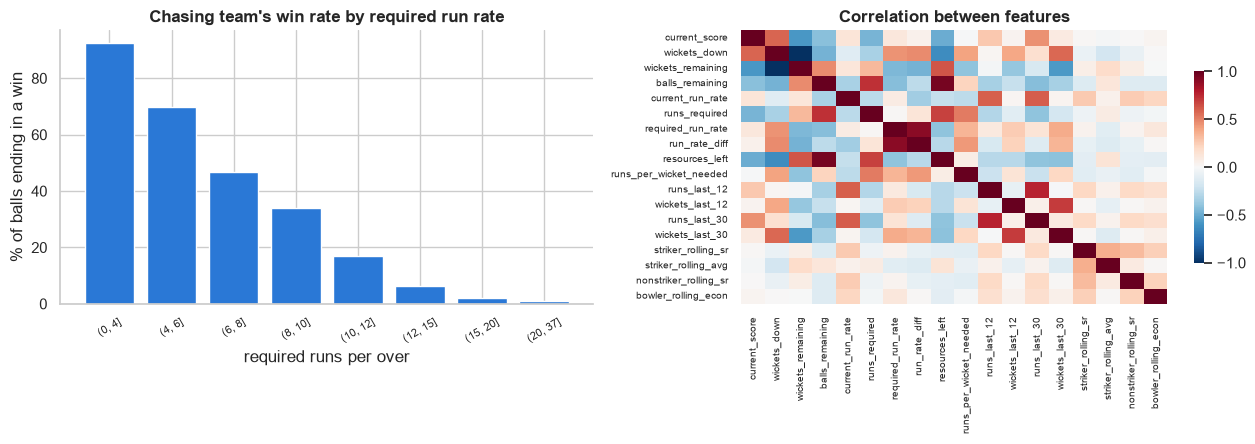

Many state features are near-duplicates of each other (see the red blocks), which is why feature importance later groups them.


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# the one relationship that matters most: required run rate against the chasing team's actual win rate
bins = pd.cut(chase["required_run_rate"], [0, 4, 6, 8, 10, 12, 15, 20, 37])
emp = chase.groupby(bins, observed=True)[LABEL].agg(["mean", "count"])
axes[0].bar(emp.index.astype(str), emp["mean"] * 100, color=BLUE)
axes[0].set(title="Chasing team's win rate by required run rate", xlabel="required runs per over", ylabel="% of balls ending in a win")
axes[0].tick_params(axis="x", rotation=30, labelsize=8)

corr = chase[STATE + MOMENTUM + FORM].corr()
sns.heatmap(corr, ax=axes[1], cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar_kws={"shrink": 0.7},
            xticklabels=True, yticklabels=True)
axes[1].set_title("Correlation between features")
axes[1].tick_params(labelsize=7)
plt.tight_layout()
plt.show()
print("Many state features are near-duplicates of each other (see the red blocks), which is why feature importance later groups them.")

## 7. Chronological split

The split is by **date**, never random. A random split would put balls from the same match on both sides, so the model would partly learn from the match it is later tested on and the score would look better than it is. Here the oldest 80% of matches train the model and the newest 20% test it.

Missing values (mainly player form for debutants) are filled with the **training-set median only**, so nothing from the test period leaks into preprocessing either.

In [19]:
from sklearn.impute import SimpleImputer

match_dates = chase.groupby("match_id")["match_date"].first().sort_values()
cutoff = match_dates.iloc[int(len(match_dates) * 0.8)]
train = chase[chase["match_date"] < cutoff].copy()
test = chase[chase["match_date"] >= cutoff].copy()
assert train["match_date"].max() < test["match_date"].min(), "train and test overlap in time"

print(f"cutoff date : {cutoff.date()}")
print(f"train       : {len(train):>9,} rows | {train.match_id.nunique():>5,} matches | {train.match_date.min().date()} to {train.match_date.max().date()}")
print(f"test        : {len(test):>9,} rows | {test.match_id.nunique():>5,} matches | {test.match_date.min().date()} to {test.match_date.max().date()}")
print(f"women's share of rows  train {train.is_female.mean():.0%}  ->  test {test.is_female.mean():.0%}   (the data shifts over time)")

imputer = SimpleImputer(strategy="median").fit(train[FEATURES])
X_train = pd.DataFrame(imputer.transform(train[FEATURES]), columns=FEATURES, index=train.index)
X_test = pd.DataFrame(imputer.transform(test[FEATURES]), columns=FEATURES, index=test.index)
y_train, y_test = train[LABEL].to_numpy(), test[LABEL].to_numpy()

cutoff date : 2024-11-16
train       :   266,460 rows | 1,800 matches | 2003-01-09 to 2024-11-15
test        :    55,058 rows |   450 matches | 2024-11-16 to 2026-09-02
women's share of rows  train 21%  ->  test 32%   (the data shifts over time)


## 8. Models

Three models are trained on **identical rows** with settings fixed in advance (nothing is tuned on the test period):

- **Logistic Regression**: a weighted sum of the inputs squeezed into a probability. Simple and fast.
- **Gradient-Boosted Trees**: many small decision trees, each correcting the previous ones (60 trees, depth 5). This is the cluster's production model family.
- **Random Forest**: many independent trees that vote (100 trees, depth 8).

Metrics, all on the held-out test period:

| Metric | Meaning | Better |
|---|---|---|
| AUC | How well the model ranks eventual winners above losers (0.5 is a coin flip) | higher |
| Brier | Average squared gap between the stated probability and what happened | lower |
| Log-Loss | Punishes confident wrong answers heavily | lower |
| ECE | Average gap between predicted and actual win rate, bucket by bucket | lower |

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

EPS = 1e-15


def ece(y, p, bins=10):
    idx = np.minimum((p * bins).astype(int), bins - 1)
    df = pd.DataFrame({"b": idx, "p": p, "y": y}).groupby("b").agg(n=("y", "size"), p=("p", "mean"), y=("y", "mean"))
    return float((df["n"] / df["n"].sum() * (df["p"] - df["y"]).abs()).sum())


def metrics(y, p):
    p = np.clip(p, EPS, 1 - EPS)
    return {"AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p), "Log-Loss": log_loss(y, p),
            "ECE": ece(y, p), "Accuracy": accuracy_score(y, p >= 0.5)}


def make_models():
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
        "Gradient-Boosted Trees": HistGradientBoostingClassifier(max_iter=60, max_depth=5, early_stopping=False, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=20, n_jobs=-1, random_state=42),
    }


models, preds, secs = make_models(), {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    preds[name] = model.predict_proba(X_test)[:, 1]
    secs[name] = time.time() - t0
    print(f"{name:<24} trained in {secs[name]:>5.1f}s")

results = pd.DataFrame({n: metrics(y_test, p) for n, p in preds.items()}).T
results["train seconds"] = pd.Series(secs)
display(results.round(4))

Logistic Regression      trained in   0.6s


Gradient-Boosted Trees   trained in   2.5s


Random Forest            trained in   3.4s


,AUC,Brier,Log-Loss,ECE,Accuracy,train seconds
Logistic Regression,0.9110,0.1209,0.3757,0.0128,0.8258,0.6136
Gradient-Boosted Trees,0.9167,0.1175,0.3617,0.0194,0.8272,2.4801
Random Forest,0.9147,0.1205,0.3745,0.0372,0.8244,3.3683


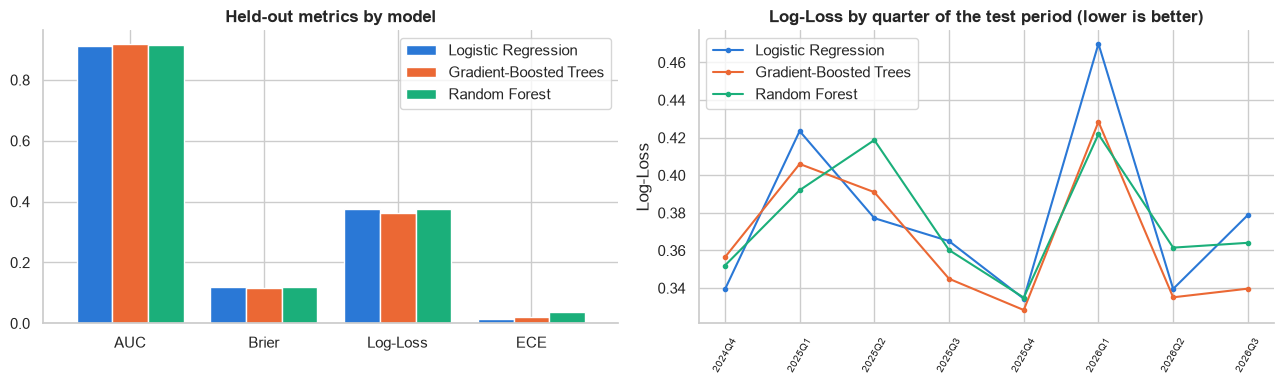

Best Log-Loss on THIS sample: Gradient-Boosted Trees (0.3617). Quarters won on Log-Loss: {'Gradient-Boosted Trees': 4, 'Logistic Regression': 2, 'Random Forest': 2}
The test period here holds only 450 chases, so the gap between the top models is small relative to the noise and the ranking can change between samples.
On the full 22,818-match cluster run Logistic Regression was marginally ahead of Gradient-Boosted Trees (Log-Loss 0.3698 vs 0.3727) and won 8 of 10 test seasons, which is why the project does not call the tree model the best: the engineered features already carry most of the non-linearity.


In [21]:
# paired by season-free simple view: which model wins most test months on Log-Loss?
test = test.assign(**{f"p_{k[:3]}": v for k, v in preds.items()})
test["month"] = test["match_date"].dt.to_period("Q").astype(str)
rows = []
for q, grp in test.groupby("month"):
    yy = grp[LABEL].to_numpy()
    rows.append({"quarter": q, **{n: log_loss(yy, np.clip(grp[f"p_{n[:3]}"], EPS, 1 - EPS)) for n in preds}})
by_q = pd.DataFrame(rows).set_index("quarter")
wins = by_q.idxmin(axis=1).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
r = results[["AUC", "Brier", "Log-Loss", "ECE"]]
r.T.plot.bar(ax=axes[0], color=[BLUE, ORANGE, GREEN], width=0.8)
axes[0].set(title="Held-out metrics by model", xlabel="")
axes[0].tick_params(axis="x", rotation=0)
by_q.plot(ax=axes[1], color=[BLUE, ORANGE, GREEN], marker="o", ms=3)
axes[1].set(title="Log-Loss by quarter of the test period (lower is better)", xlabel="", ylabel="Log-Loss")
axes[1].tick_params(axis="x", rotation=60, labelsize=7)
plt.tight_layout()
plt.show()
best = results["Log-Loss"].idxmin()
print(f"Best Log-Loss on THIS sample: {best} ({results['Log-Loss'].min():.4f}). Quarters won on Log-Loss: {wins.to_dict()}")
print(f"The test period here holds only {test.match_id.nunique()} chases, so the gap between the top models is small relative to the noise and the ranking can change between samples.")
print("On the full 22,818-match cluster run Logistic Regression was marginally ahead of Gradient-Boosted Trees (Log-Loss 0.3698 vs 0.3727) and won 8 of 10 test seasons, "
      "which is why the project does not call the tree model the best: the engineered features already carry most of the non-linearity.")

## 9. Calibration: are the percentages honest?

A model can rank winners well and still be over-confident. If it says "70%" for a thousand situations, about 700 of those chasing teams should win. A **reliability chart** plots stated probability against what actually happened; a perfect model sits on the diagonal.

Correcting the probabilities needs a calibrator (and whether it helps depends on how much data it sees, as the result below shows), and the calibrator must be **fitted on data the model did not train on** (on training data the model is already calibrated, so there would be nothing to learn). So the test period is cut in two by date: the first half fits the calibrator, the second half judges it, and the judging half is never used for fitting.

Two calibrators are compared: **Platt scaling** (a logistic curve through the scores) and **Isotonic regression** (a step function that only has to go up). The isotonic output is clipped to [0.5%, 99.5%] so a display never claims certainty.

In [22]:
from sklearn.isotonic import IsotonicRegression

PROB_FLOOR, PROB_CEIL = 0.005, 0.995              # the same limits the cluster uses
p_gbt = preds["Gradient-Boosted Trees"]

split_date = test["match_date"].sort_values().iloc[len(test) // 2]
is_cal = (test["match_date"] < split_date).to_numpy()
y_cal, y_eval = y_test[is_cal], y_test[~is_cal]
p_cal, p_eval = p_gbt[is_cal], p_gbt[~is_cal]
print(f"calibration half: {is_cal.sum():,} rows (before {split_date.date()}) | judging half: {(~is_cal).sum():,} rows")

iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(p_cal, y_cal)
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = LogisticRegression().fit(logit(p_cal).reshape(-1, 1), y_cal)

versions = {"raw (uncalibrated)": p_eval,
            "Platt scaling": platt.predict_proba(logit(p_eval).reshape(-1, 1))[:, 1],
            "Isotonic": iso.predict(p_eval),
            "Isotonic + clip": np.clip(iso.predict(p_eval), PROB_FLOOR, PROB_CEIL)}
cal_table = pd.DataFrame({k: metrics(y_eval, v) for k, v in versions.items()}).T
display(cal_table.round(4))

calibration half: 27,466 rows (before 2025-11-11) | judging half: 27,592 rows


,AUC,Brier,Log-Loss,ECE,Accuracy
raw (uncalibrated),0.9238,0.1126,0.3442,0.0202,0.8321
Platt scaling,0.9238,0.1144,0.3497,0.0371,0.8329
Isotonic,0.9232,0.1145,0.3789,0.0363,0.8323
Isotonic + clip,0.9232,0.1145,0.3534,0.0356,0.8323


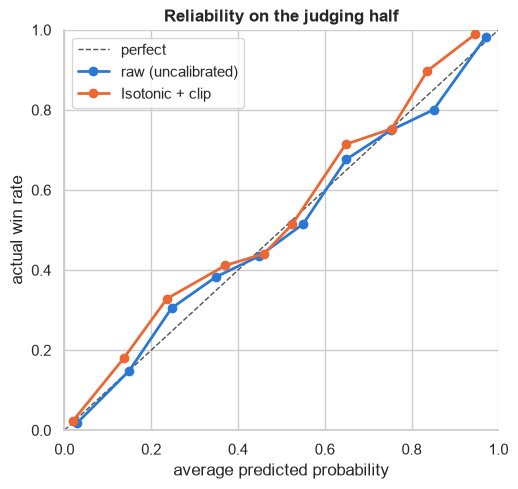

Points below the diagonal mean the model was too optimistic for the chasing team.
On THIS sample the calibrator did not help: Log-Loss 0.3442 -> 0.3534, ECE 0.0202 -> 0.0356.
Likely reason (not tested here): the calibration half holds only about 216 chases, and balls within a chase are strongly correlated, so a flexible step function (isotonic) fits the quirks of those few matches rather than a general pattern. Unclipped isotonic is worse still (see the table), which is why the output is clipped.
On the full-data cluster run (about 9,000 chases in the test period) calibration did help: Log-Loss 0.3718 -> 0.3682 and ECE 0.0188 -> 0.0108 on the judging seasons. The lesson: calibration needs enough independent matches, so check the result every time instead of assuming it helps.


In [23]:
def reliability(y, p, bins=10):
    idx = np.minimum((p * bins).astype(int), bins - 1)
    return pd.DataFrame({"b": idx, "p": p, "y": y}).groupby("b").agg(n=("y", "size"), predicted=("p", "mean"), actual=("y", "mean"))

fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="perfect")
for name, colour in [("raw (uncalibrated)", BLUE), ("Isotonic + clip", ORANGE)]:
    rel = reliability(y_eval, versions[name])
    ax.plot(rel["predicted"], rel["actual"], marker="o", lw=2, color=colour, label=name)
ax.set(title="Reliability on the judging half", xlabel="average predicted probability", ylabel="actual win rate", xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.show()
raw_ll, iso_ll = cal_table.loc["raw (uncalibrated)", "Log-Loss"], cal_table.loc["Isotonic + clip", "Log-Loss"]
raw_e, iso_e = cal_table.loc["raw (uncalibrated)", "ECE"], cal_table.loc["Isotonic + clip", "ECE"]
print("Points below the diagonal mean the model was too optimistic for the chasing team.")
if iso_ll < raw_ll and iso_e < raw_e:
    print(f"On this sample the calibrator helped: Log-Loss {raw_ll:.4f} -> {iso_ll:.4f}, ECE {raw_e:.4f} -> {iso_e:.4f}.")
else:
    print(f"On THIS sample the calibrator did not help: Log-Loss {raw_ll:.4f} -> {iso_ll:.4f}, ECE {raw_e:.4f} -> {iso_e:.4f}.")
    print(f"Likely reason (not tested here): the calibration half holds only about {test.loc[is_cal, 'match_id'].nunique()} chases, and balls within a chase are strongly correlated, "
          "so a flexible step function (isotonic) fits the quirks of those few matches rather than a general pattern. "
          "Unclipped isotonic is worse still (see the table), which is why the output is clipped.")
print("On the full-data cluster run (about 9,000 chases in the test period) calibration did help: Log-Loss 0.3718 -> 0.3682 and ECE 0.0188 -> 0.0108 on the judging seasons. "
      "The lesson: calibration needs enough independent matches, so check the result every time instead of assuming it helps.")

## 10. Win Probability Added (WPA)

**WPA** turns the model into a story: for each ball, how much did the chasing team's win probability change? A wicket that drops the probability from 62% to 41% has a WPA of -0.21. Because each WPA is the difference of two consecutive probabilities, a chase's WPAs add up exactly to its final probability minus its first, which is the check used on the cluster.

The match below is the one with the most back-and-forth (the probability crossed 50% most often) in the judging half.

telescoping check over 234 chases: largest error 3.33e-16
match 1547880: Glasgow Cosmic v Rotterdam Dockers, 2026-09-01, T20; chasing team Rotterdam Dockers, won = True


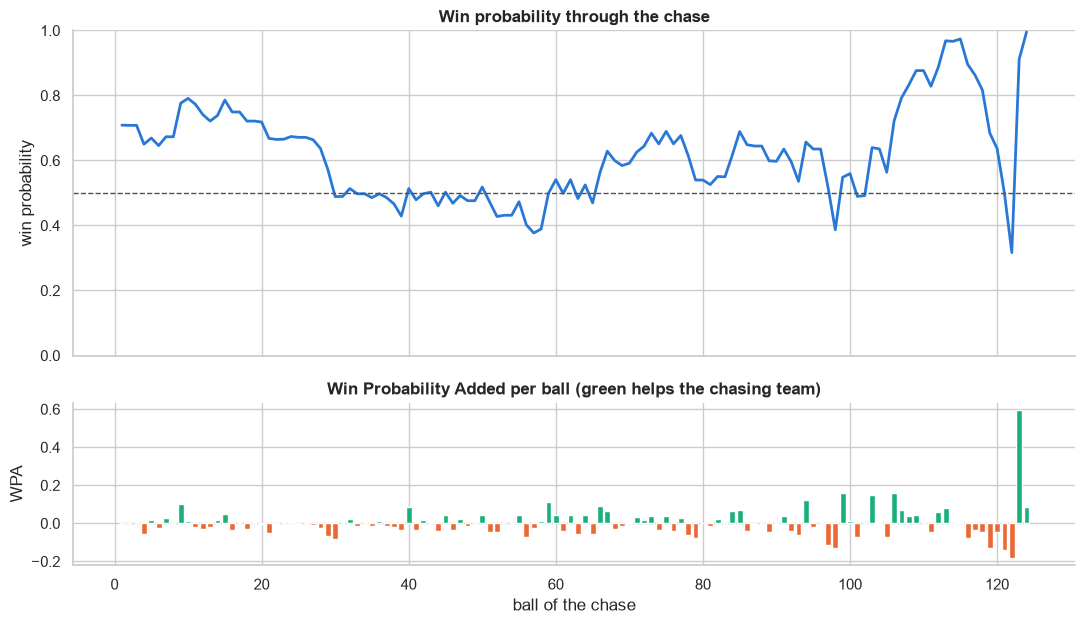

,ball_seq,batter,bowler,before,after,wpa
122,123,D Wiese,Ali Khan,0.317,0.911,0.595
121,122,BR McDermott,Ali Khan,0.498,0.317,-0.182
98,99,BAD Manenti,PA van Meekeren,0.387,0.548,0.161
105,106,BAD Manenti,L Ngidi,0.564,0.722,0.158
102,103,BR McDermott,L Ngidi,0.492,0.640,0.148


In [24]:
scored = test.assign(prob=p_gbt).loc[~is_cal].copy()
scored["prev_prob"] = scored.groupby("match_id", sort=False)["prob"].shift(1)
scored["wpa"] = scored["prob"] - scored["prev_prob"]                          # NaN on the first ball of every chase

# exact telescoping: sum of WPA = last probability - first probability, for every chase
tele = scored.groupby("match_id").apply(lambda g: abs(g["wpa"].sum() - (g["prob"].iloc[-1] - g["prob"].iloc[0])), include_groups=False)
print(f"telescoping check over {len(tele):,} chases: largest error {tele.max():.2e}")
assert tele.max() < 1e-9

crossings = scored.groupby("match_id", sort=False)["prob"].apply(lambda s: int((np.diff((s.to_numpy() > 0.5).astype(int)) != 0).sum()))
mid = crossings[scored.groupby("match_id")["balls_completed_in_innings"].max().reindex(crossings.index) >= 100].idxmax()
one = scored[scored["match_id"] == mid].reset_index(drop=True)
info_row = matches[matches.match_id == mid].iloc[0]
print(f"match {mid}: {info_row.team1} v {info_row.team2}, {info_row.match_date.date()}, {info_row.match_type}; "
      f"chasing team {one.batting_team.iloc[0]}, won = {bool(one.label.iloc[0])}")

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(one["ball_seq"], one["prob"], color=BLUE, lw=2)
axes[0].axhline(0.5, color=GREY, ls="--", lw=1)
axes[0].set(title="Win probability through the chase", ylabel="win probability", ylim=(0, 1))
axes[1].bar(one["ball_seq"], one["wpa"].fillna(0), color=np.where(one["wpa"].fillna(0) >= 0, GREEN, ORANGE))
axes[1].set(title="Win Probability Added per ball (green helps the chasing team)", xlabel="ball of the chase", ylabel="WPA")
plt.tight_layout()
plt.show()

top = one.reindex(one["wpa"].abs().sort_values(ascending=False, na_position="last").index).head(5)
display(top[["ball_seq", "batter", "bowler", "prev_prob", "prob", "wpa"]].rename(columns={"prev_prob": "before", "prob": "after"}).round(3))

## 11. Feature importance: what does the model rely on?

Many features are near-duplicates (runs required, required rate, rate difference all describe the same pressure), so a single feature's importance can mislead. Instead, **whole groups** of related features are scrambled together: the rows' values for that group are swapped for another random row's values, and the rise in Log-Loss shows how much the model depended on the group. This is **permutation importance**, measured on test data.

Gradient-Boosted Trees: baseline Log-Loss on the sample = 0.3617


Logistic Regression: baseline Log-Loss on the sample = 0.3757


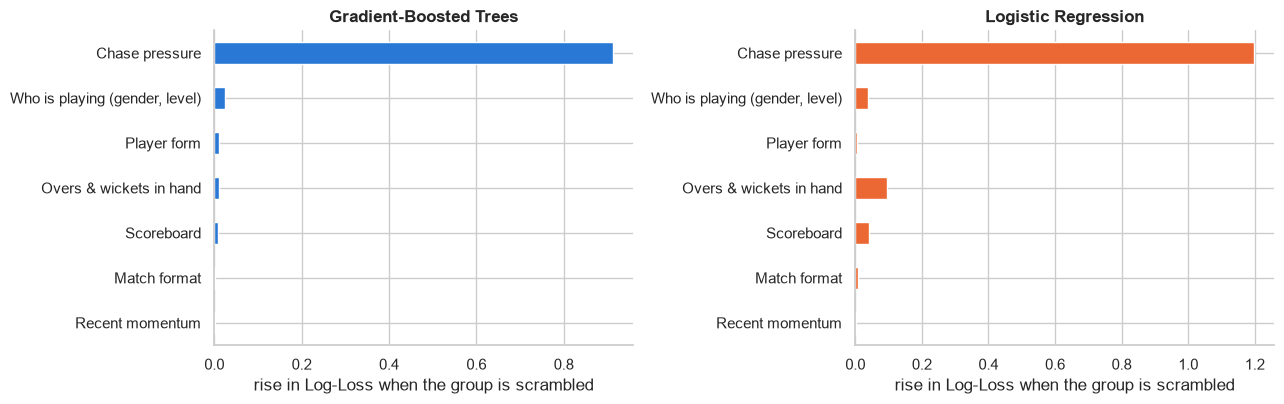

,Gradient-Boosted Trees,Logistic Regression
Chase pressure,0.9128,1.1978
"Who is playing (gender, level)",0.0245,0.0369
Player form,0.0109,0.0037
Overs & wickets in hand,0.0107,0.0950
Scoreboard,0.0073,0.0400
Match format,0.0015,0.0078
Recent momentum,0.0008,0.0006


Chase pressure dominates everything. Player form is a modest contributor; recent momentum adds almost nothing once the state is known.


In [25]:
GROUPS = {
    "Chase pressure": ["runs_required", "required_run_rate", "run_rate_diff", "runs_per_wicket_needed"],
    "Overs & wickets in hand": ["balls_remaining", "wickets_down", "wickets_remaining", "resources_left"],
    "Scoreboard": ["current_score", "current_run_rate"],
    "Recent momentum": MOMENTUM,
    "Player form": FORM,
    "Match format": FORMAT,
    "Who is playing (gender, level)": CONTEXT,
}
assert sorted(c for g in GROUPS.values() for c in g) == sorted(FEATURES), "groups must cover every feature exactly once"


def permutation_importance(model, X, y, repeats=2, seed=0):
    rng = np.random.default_rng(seed)
    base = log_loss(y, np.clip(model.predict_proba(X)[:, 1], EPS, 1 - EPS))
    out = {}
    for name, cols in GROUPS.items():
        rises = []
        for _ in range(repeats):
            shuffled = X.copy()
            shuffled[cols] = X[cols].to_numpy()[rng.permutation(len(X))]      # shuffle the group jointly
            rises.append(log_loss(y, np.clip(model.predict_proba(shuffled)[:, 1], EPS, 1 - EPS)) - base)
        out[name] = float(np.mean(rises))
    return base, out


sub_idx = np.random.default_rng(1).choice(len(X_test), min(120_000, len(X_test)), replace=False)
imp = {}
for name in ["Gradient-Boosted Trees", "Logistic Regression"]:
    base, imp[name] = permutation_importance(models[name], X_test.iloc[sub_idx], y_test[sub_idx])
    print(f"{name}: baseline Log-Loss on the sample = {base:.4f}")

imp_df = pd.DataFrame(imp).sort_values("Gradient-Boosted Trees", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, colour in [(axes[0], "Gradient-Boosted Trees", BLUE), (axes[1], "Logistic Regression", ORANGE)]:
    imp_df[col].plot.barh(ax=ax, color=colour)
    ax.set(title=f"{col}", xlabel="rise in Log-Loss when the group is scrambled")
plt.tight_layout()
plt.show()
display(imp_df.sort_values("Gradient-Boosted Trees", ascending=False).round(4))
print("Chase pressure dominates everything. Player form is a modest contributor; recent momentum adds almost nothing once the state is known.")

## 12. Gender and level: the missing-context finding

Early in the project the model could not tell men's cricket from women's, or international from club, and its probabilities were too optimistic for women's matches. Women's cricket also grew from a small share of the data to a large one, so the problem got worse in the test period.

Two features fix most of it: `is_female` and `is_international`. This section trains the same Gradient-Boosted Trees model **with and without** them and measures:

1. the paired change in Log-Loss, with a 95% interval that **resamples whole matches** (balls within one chase are not independent, so a plain interval would be too narrow), and
2. the raw calibration gap in the 45-85% band for each gender and level (predicted minus actual win rate; 0 is perfect).

paired change in Log-Loss with context features: -0.00253   95% interval [-0.01604, +0.01097] over 450 chases
verdict: not distinguishable from zero on this sample


,rows,chases,without context,with context
segment,,,,
male club,19436,156,-0.009,0.010
male international,17942,142,0.065,0.063
female international,14968,125,0.141,0.062
female club,2712,27,-0.105,-0.169


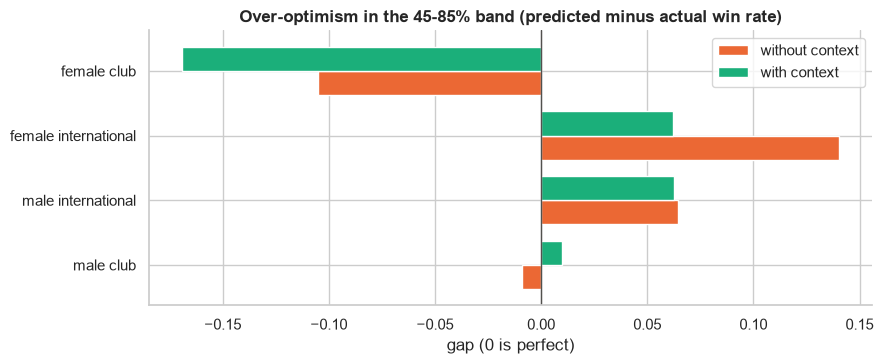

In [26]:
no_ctx = [f for f in FEATURES if f not in CONTEXT]
m_no = HistGradientBoostingClassifier(max_iter=60, max_depth=5, early_stopping=False, random_state=42).fit(X_train[no_ctx], y_train)
p_no = m_no.predict_proba(X_test[no_ctx])[:, 1]
p_with = p_gbt

row_ll = lambda p: -(y_test * np.log(np.clip(p, EPS, 1)) + (1 - y_test) * np.log(np.clip(1 - p, EPS, 1)))
delta = pd.DataFrame({"match_id": test["match_id"].to_numpy(), "d": row_ll(p_with) - row_ll(p_no)})
cl = delta.groupby("match_id")["d"].agg(s="sum", m="size")
N = cl["m"].sum()
mean = cl["s"].sum() / N
se = np.sqrt(((cl["s"] - mean * cl["m"]) ** 2).sum()) / N
lo, hi = mean - 1.96 * se, mean + 1.96 * se
print(f"paired change in Log-Loss with context features: {mean:+.5f}   95% interval [{lo:+.5f}, {hi:+.5f}] over {len(cl):,} chases")
print("verdict:", "a real improvement (interval excludes zero)" if hi < 0 else "not distinguishable from zero on this sample")

band = lambda p: (p >= 0.45) & (p < 0.85)
rows = []
for (g_, t_), idx in test.groupby(["gender", "team_type"]).groups.items():
    pos_ = test.index.get_indexer(idx)
    row = {"segment": f"{g_} {t_}", "rows": len(pos_), "chases": test.iloc[pos_]["match_id"].nunique()}
    for label, p in [("without context", p_no), ("with context", p_with)]:
        sel = pos_[band(p[pos_])]
        row[label] = (p[sel].mean() - y_test[sel].mean()) if len(sel) >= 200 else np.nan
    rows.append(row)
seg = pd.DataFrame(rows).set_index("segment").sort_values("rows", ascending=False)
display(seg.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
seg[["without context", "with context"]].plot.barh(ax=ax, color=[ORANGE, GREEN], width=0.75)
ax.axvline(0, color=GREY, lw=1)
ax.set(title="Over-optimism in the 45-85% band (predicted minus actual win rate)", xlabel="gap (0 is perfect)", ylabel="")
plt.tight_layout()
plt.show()

The "chases" column shows how few independent matches some segments have (women's club cricket especially), which is why its gap can swing wildly: treat any segment under a few hundred chases as noise. On the full 22,818-match run the improvement was -0.0053 in Log-Loss (95% interval -0.0073 to -0.0034, better in 9 of 10 test seasons), and the women's calibration gap fell by about 60% but did not disappear. A smaller sample like this one gives a wider interval and noisier segment gaps, especially for the smaller segments.

## 13. Batter vs bowler: why it is a lookup, not a feature

It is tempting to add "how has this batter done against this bowler before?" as a feature. The data says otherwise: most pairs have met for only a handful of balls. The cluster table (`matchup_lookup`) therefore keeps head-to-head as a **lookup with reliability tiers** rather than a model input. The same tiers are applied here.

| Tier | Balls faced |
|---|---|
| thin | fewer than 12 |
| limited | 12-29 |
| moderate | 30-59 |
| solid | 60 or more |

112,324 batter-bowler pairs; share with under 12 balls: 86% (cluster, all matches: 877,540 of 1,168,224 = 75%)


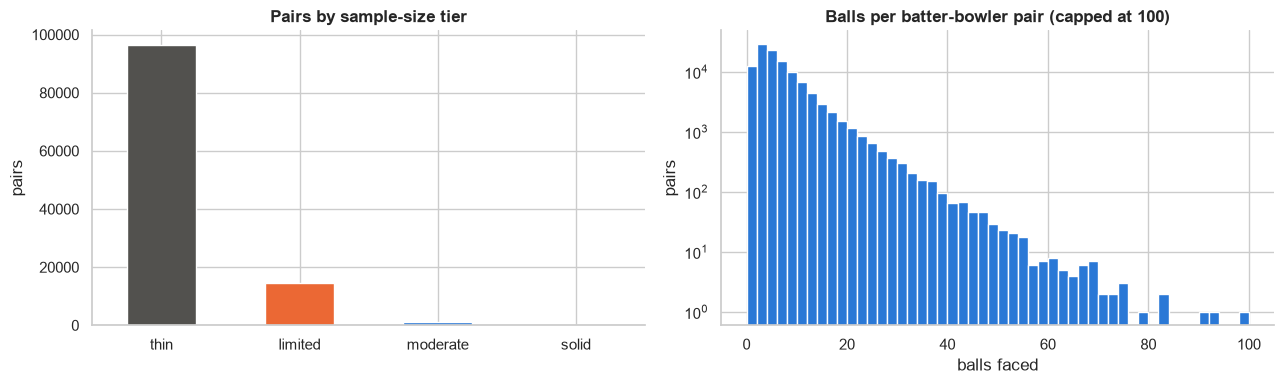

,batter,bowler,balls,runs,dismissals,strike_rate,tier
34725,BRM Taylor,Shakib Al Hasan,105,37,2,35.2,solid
80584,V Kohli,K Rabada,93,82,0,88.2,solid
30041,PG Raut,A Shrubsole,91,46,2,50.5,solid
64426,HE van der Dussen,AU Rashid,83,83,0,100.0,solid
80602,V Kohli,L Ngidi,82,68,1,82.9,solid
19787,H Masakadza,Shakib Al Hasan,79,95,0,120.3,solid
100481,SJ Taylor,JL Jonassen,75,97,0,129.3,solid
94427,M Kaif,SB Styris,74,64,1,86.5,solid


In [27]:
pair = deliveries.dropna(subset=["batter_id", "bowler_id"]).copy()
pair["faced"] = (pair["extra_wides"] == 0).astype(int)
pair["dismissed"] = (pair["player_out_id"] == pair["batter_id"]) & pair["wicket_kind"].isin(BOWLER_WICKETS)
mu = (pair.groupby(["batter_id", "bowler_id"])
          .agg(balls=("faced", "sum"), runs=("runs_batter", "sum"), dismissals=("dismissed", "sum"),
               batter=("batter", "first"), bowler=("bowler", "first")).reset_index())
mu["strike_rate"] = 100 * mu["runs"] / mu["balls"].clip(lower=1)
mu["tier"] = pd.cut(mu["balls"], [-1, 11, 29, 59, 10**9], labels=["thin", "limited", "moderate", "solid"])

tiers = mu["tier"].value_counts().reindex(["thin", "limited", "moderate", "solid"])
print(f"{len(mu):,} batter-bowler pairs; share with under 12 balls: {tiers['thin'] / len(mu):.0%} (cluster, all matches: 877,540 of 1,168,224 = 75%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
tiers.plot.bar(ax=axes[0], color=[GREY, ORANGE, BLUE, GREEN])
axes[0].set(title="Pairs by sample-size tier", xlabel="", ylabel="pairs")
axes[0].tick_params(axis="x", rotation=0)
axes[1].hist(mu["balls"].clip(upper=100), bins=50, color=BLUE)
axes[1].set(title="Balls per batter-bowler pair (capped at 100)", xlabel="balls faced", ylabel="pairs", yscale="log")
plt.tight_layout()
plt.show()

display(mu[mu.tier == "solid"].sort_values("balls", ascending=False).head(8)[["batter", "bowler", "balls", "runs", "dismissals", "strike_rate", "tier"]].round(1))

## 14. Full-data results from the cluster

Everything above ran on a sample. The real pipeline ran on all 22,818 matches with Spark and wrote its results to Hive; `dashboard/export_snapshots.sh` copies them to `dashboard/data_cache/`. If those files are present, this section loads them so the two runs can be compared directly.

this notebook (sample)                           \
                                          AUC   Brier Log-Loss     ECE   
Logistic Regression                    0.9110  0.1209   0.3757  0.0128   
Gradient-Boosted Trees                 0.9167  0.1175   0.3617  0.0194   
Random Forest                          0.9147  0.1205   0.3745  0.0372   

                                cluster (all matches)                   \
                       Accuracy                   AUC   Brier Log-Loss   
Logistic Regression      0.8258                0.9140  0.1192   0.3698   
Gradient-Boosted Trees   0.8272                0.9133  0.1201   0.3727   
Random Forest            0.8244                0.9054  0.1264   0.3974   

                                         
                           ECE Accuracy  
Logistic Regression     0.0093   0.8262  
Gradient-Boosted Trees  0.0164   0.8248  
Random Forest           0.0333   0.8186

Both runs split by date and use the same features and fixed settings, so the ordering of the models and the size of the numbers should be close.


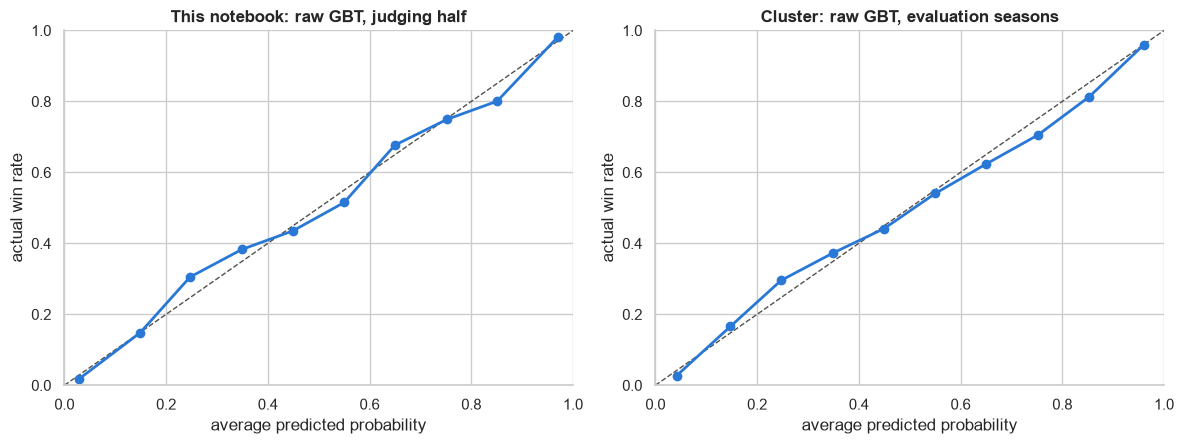

In [28]:
def snapshot(name):
    path = SNAPSHOTS / f"{name}.tsv"
    return pd.read_csv(path, sep="\t") if path.exists() else None


mc, fi, cb = snapshot("model_comparison"), snapshot("feature_importance"), snapshot("calibration_buckets")
if mc is None:
    print("Cluster snapshots not found (run dashboard/export_snapshots.sh with the cluster up). Skipping the comparison.")
else:
    mine = results[["AUC", "Brier", "Log-Loss", "ECE", "Accuracy"]].copy()
    theirs = mc.set_index("model")[["auc", "brier", "logloss", "ece", "accuracy"]]
    theirs.columns = mine.columns
    both = pd.concat({"this notebook (sample)": mine, "cluster (all matches)": theirs.reindex(mine.index)}, axis=1)
    display(both.round(4))
    print("Both runs split by date and use the same features and fixed settings, so the ordering of the models and the size of the numbers should be close.")

    if cb is not None:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
        rel = reliability(y_eval, p_eval)
        for ax, (title, pred, act, n) in zip(axes, [("This notebook: raw GBT, judging half", rel["predicted"], rel["actual"], rel["n"]),
                                                    ("Cluster: raw GBT, evaluation seasons", cb["raw_pred"], cb["actual"], cb["n"])]):
            ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
            ax.plot(pred, act, marker="o", color=BLUE, lw=2)
            ax.set(title=title, xlabel="average predicted probability", ylabel="actual win rate", xlim=(0, 1), ylim=(0, 1))
        plt.tight_layout()
        plt.show()

## 15. How these steps run on the cluster

The notebook uses pandas so it runs anywhere. On the cluster the same logic is written with Spark window functions, which is what lets it scale from a 2,500-match sample to all 22,818 matches. For example, the momentum window in this notebook (`cumsum` minus a lagged `cumsum`) is, in `features/match_state_features.py`:

```python
ball_order = Window.partitionBy("match_id", "innings_num").orderBy("over", "delivery_idx")
w = ball_order.rowsBetween(-n, -1)            # the upper bound of -1 excludes the current ball
df = df.withColumn(f"runs_last_{n}", F.coalesce(F.sum("runs_total").over(w), F.lit(0)))
```

and the rolling player form (section 6.2) is, in `features/player_form_features.py`:

```python
form_window = (Window.partitionBy("player_id")
               .orderBy("match_date", "match_id")
               .rowsBetween(-FORM_WINDOW, -1))      # previous 10 matches, current match excluded
```

| Notebook section | Repository file | How to run on the cluster |
|---|---|---|
| 2-3 Load and process | `etl/flatten_matches.py` | `docker exec spark-master $SUBMIT /workspace/etl/flatten_matches.py` |
| 5 MapReduce | `mapreduce/mapper.py`, `reducer.py`, `run_job.sh` | `bash mapreduce/run_job.sh` |
| 6 Features | `features/match_state_features.py`, `player_form_features.py`, `build_training_table.py` | `spark-submit` each in turn |
| 7-8 Split and models | `ml/train_win_probability.py`, `ml/compare_models.py` | `spark-submit` |
| 9 Calibration | `ml/calibrate_win_probability.py` | `spark-submit` |
| 10 WPA | `ml/compute_wpa.py` | `spark-submit` |
| 11 Importance | `ml/feature_importance.py` | `spark-submit` |
| 12 Context | `ml/verify_context_adoption.py` | `spark-submit` |
| 13 Matchups | `features/matchup_lookup.py` | `spark-submit` |

The complete commands are in `docs/RUNNING.md`.

## 16. Summary and limits

**What this notebook showed, end to end**

1. Raw nested JSON becomes one row per delivery, with the project's rules for legal balls, phases and dot balls (each rule checked, not assumed).
2. The project's own MapReduce mapper and reducer reproduce a pandas group-by exactly.
3. Features are built so that nothing from the future leaks in, and the momentum and form windows are verified against brute-force recomputation.
4. The model is trained on the past and tested on the future, and three models are compared fairly.
5. The probabilities are checked for honesty, corrected on data the model never trained on, and turned into a ball-by-ball story with Win Probability Added.
6. Importance is measured by group, and the gender/level finding is tested with an interval that respects the match structure.

**Limits to keep in mind**

- This is a **sample** run with scikit-learn. The cluster results in section 14 are the full-data ones and are the figures to quote.
- Models were not tuned; settings were fixed in advance.
- Matchup data is too sparse to be a feature, so it is a lookup only.
- Some segments (for example women's club cricket) are small in a sample, so their numbers are noisy.
- The model is historical and batch; there is no live data feed.

### Glossary

| Term | Meaning |
|---|---|
| Legal ball | A delivery that is not a wide or a no-ball |
| Dot ball | A legal ball on which the bowler is charged no runs |
| Phase | Powerplay, middle or death overs (the boundaries depend on the format) |
| Chase | The second innings, where the batting side has a target |
| Leakage | The model seeing information it would not have had in real life |
| Chronological split | Train on earlier matches, test on later ones |
| Brier score | Average squared gap between stated probability and outcome (lower is better) |
| Log-Loss | A penalty that is harsh on confident wrong answers (lower is better) |
| AUC | How well the model ranks winners above losers (higher is better) |
| ECE | Average gap between predicted and actual win rate across probability buckets |
| Calibration | Making a stated "70%" really mean about 70% |
| WPA | Win Probability Added: the change in win probability caused by one ball |
| Permutation importance | The worsening of the model when a group of features is scrambled |